# Aviation Cybersecurity Risk Agent – End-to-End AI Solution with Gemini

**Lab 1.5 – Demonstration of an End-to-End AI Solution in Google Colab using the Gemini API**

## What this notebook does

This notebook implements the thesis-based AI system as **one single AI agent**.

- **Input (X):** a free-text description of an airport's cybersecurity governance.
- **Output (y):** `Low` or `High` cybersecurity risk, plus scores, an explanation and recommendations.
- **Basis:** three articles on aviation cybersecurity – Mizrak & Akkartal (2024), Dave et al. (2022) and AlMarri, Bahroun & Hassan (2026).
- **The 7 criteria** (from Mizrak & Akkartal): TDS (threat detection), DEP (data encryption/protection), RC (regulatory compliance), IRP (incident response plan), UT (user training), ACM (access control management), NSS (network security).
- **Decision rule:** average maturity score of the 7 criteria. `>= 0.5` is **Low** risk, `< 0.5` is **High** risk.

The notebook reuses the two prompts from Lab 1.4 (`/prompts/` in the GitHub repository): **Prompt 1** (zero-shot) and **Prompt 2** (few-shot).

## Notebook structure

1. Setup and secure API key
2. Pipeline design (diagram)
3. The two prompts from Lab 1.4
4. The agent and the pipeline stages
5. Prompt 1 – zero-shot run
6. Prompt 2 – few-shot run
7. Comparison of the two runs
8. consistency test
9. Reflection

In [ ]:
!pip install -q google-genai

In [ ]:
import os
import json
import re
import time
import statistics

import pandas as pd
import matplotlib.pyplot as plt
from google import genai
from google.genai import types, errors

# Load the key from Colab Secrets (never hardcode it).
try:
    from google.colab import userdata
    GEMINI_KEY = userdata.get('GEMINI_KEY')
except ImportError:
    # Only used when the notebook is run outside Colab (for example local tests).
    GEMINI_KEY = os.environ.get('GEMINI_KEY')

assert GEMINI_KEY, "GEMINI_KEY not found. Add it in Colab Secrets and enable notebook access."

client = genai.Client(api_key=GEMINI_KEY)

# Models are retired from time to time, so the notebook asks Google which models this key can use.
PREFERRED = ["gemini-3.8-flash", "gemini-flash-latest"]


def list_flash_models():
    # Flash models of this API key that support generateContent (newest names first, 'lite' last)
    names = []
    try:
        for m in client.models.list():
            name = m.name.replace("models/", "")
            actions = getattr(m, "supported_actions", None) or []
            skip = ["image", "tts", "live", "audio", "embedding", "robotics", "computer-use"]
            if "generateContent" in actions and "flash" in name and not any(x in name for x in skip):
                names.append(name)
    except Exception as e:
        print("Could not list models:", str(e)[:200])
    names.sort(reverse=True)
    names.sort(key=lambda n: "lite" in n)  # stable: non-lite models first
    return names


MODEL_CANDIDATES = list(dict.fromkeys(PREFERRED + list_flash_models()))
print("Models to try:", MODEL_CANDIDATES)

MODEL = None
for candidate in MODEL_CANDIDATES:
    for attempt in range(3):
        try:
            client.models.generate_content(model=candidate, contents="Reply with the word OK.")
            MODEL = candidate
            break
        except Exception as e:
            code = getattr(e, "code", None)
            print(f"Model {candidate} not usable ({code}): {str(e)[:300]}")
            if code in (500, 502, 503, 504) and attempt < 2:
                wait = 5 * 2 ** attempt
                print(f"  Server busy. Waiting {wait}s and trying again...")
                time.sleep(wait)
                continue
            break  # 404, 429 and other errors: go to the next model
    if MODEL:
        break

assert MODEL, ("No Gemini model worked. If you see 429, the free quota is used up: wait, check "
               "aistudio.google.com/usage, or create a new key in a new project.")

print("Gemini client ready. Model:", MODEL)

Models to try: ['gemini-3.8-flash', 'gemini-flash-latest', 'gemini-omni-flash-preview', 'gemini-omni-1.2-flash', 'gemini-omni-1.1-flash', 'gemini-3.7-flash', 'gemini-3.6-flash', 'gemini-3.5-flash', 'gemini-3-flash-preview', 'gemini-2.5-flash', 'gemini-flash-lite-latest', 'gemini-3.5-flash-lite', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-lite', 'gemini-2.5-flash-lite']
Model gemini-3.8-flash not usable (503): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
  Server busy. Waiting 5s and trying again...
Model gemini-3.8-flash not usable (503): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
  Server busy. Waiting 10s and trying again...
Model gemini-3.8-flash not usable (503): 503 UNAVAILABL

## 2. Pipeline design

The agent receives X and goes through four stages. The first three are done by the Gemini model inside one prompt; the last stages are checked and displayed by the notebook code, so the final decision can always be verified.

| Stage  | What happens |
|---|------|
| 1. Data understanding |   Reads X and finds evidence for each of the 7 criteria |
| 2. Inference |  Gives each criterion a maturity score from 0 to 1 |
| 3. Reasoning |  Gemini computes the average and applies the 0.5 rule; the code **recomputes** it to check |
| 4. Output generation |  JSON result: y, scores, explanation, recommendations; the code prints a report and a chart |

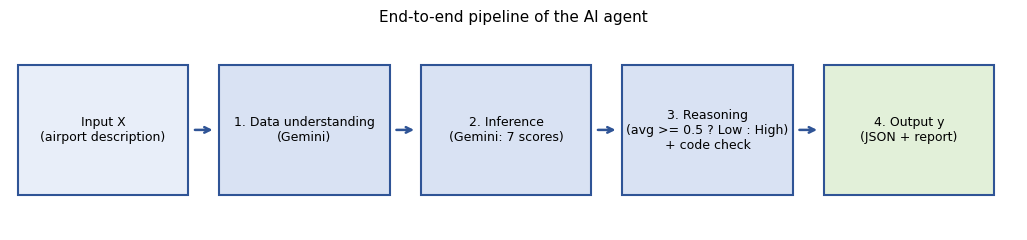

In [ ]:
def draw_pipeline():
    steps = [
        ("Input X\n(airport description)", "#E8EEF9"),
        ("1. Data understanding\n(Gemini)", "#D9E2F3"),
        ("2. Inference\n(Gemini: 7 scores)", "#D9E2F3"),
        ("3. Reasoning\n(avg >= 0.5 ? Low : High)\n+ code check", "#D9E2F3"),
        ("4. Output y\n(JSON + report)", "#E2F0D9"),
    ]
    fig, ax = plt.subplots(figsize=(13, 2.6))
    ax.set_xlim(0, len(steps) * 2.6)
    ax.set_ylim(0, 2)
    ax.axis("off")
    for i, (text, color) in enumerate(steps):
        x = i * 2.6 + 0.1
        ax.add_patch(plt.Rectangle((x, 0.35), 2.2, 1.3, facecolor=color, edgecolor="#2F5496", linewidth=1.5))
        ax.text(x + 1.1, 1.0, text, ha="center", va="center", fontsize=9)
        if i < len(steps) - 1:
            ax.annotate("", xy=(x + 2.55, 1.0), xytext=(x + 2.25, 1.0),
                        arrowprops=dict(arrowstyle="->", color="#2F5496", lw=1.8))
    ax.set_title("End-to-end pipeline of the AI agent", fontsize=11)
    plt.show()

draw_pipeline()

## 3. The two prompts from Lab 1.4

The prompts are recreated here from the `/prompts/` directory of the repository.

- **Prompt 1 (zero-shot):** the instructions and one new observation X, with no examples.
- **Prompt 2 (few-shot):** the same instructions, plus 5 known (X, y) pairs from Lab 1.2 (`data/examples.csv`) before the new observation.

The same new observation X is used in both, so the results can be compared directly.

In [ ]:
CRITERIA = ["TDS", "DEP", "RC", "IRP", "UT", "ACM", "NSS"]
THRESHOLD = 0.5

AGENT_INSTRUCTIONS = """You are an AI agent that works as an end-to-end aviation cybersecurity risk classifier.

TASK
You receive a text description X of an aviation organisation (for example an airport).
Run these stages and return the final result y.

STAGE 1 - DATA UNDERSTANDING
Read X and find evidence for each of these 7 criteria:
TDS (threat detection), DEP (data encryption/protection), RC (regulatory compliance),
IRP (incident response plan), UT (user training), ACM (access control management),
NSS (network security). If X says nothing about a criterion, say so and give it 0.3.

STAGE 2 - INFERENCE
Give each criterion a maturity score from 0.0 (absent) to 1.0 (excellent).

STAGE 3 - REASONING
Compute avg_score = mean of the 7 scores.
Decision rule: avg_score >= 0.5 -> "Low" risk; avg_score < 0.5 -> "High" risk.
Identify the 2 weakest criteria.

STAGE 4 - OUTPUT GENERATION
Return ONLY valid JSON with this format:
{
  "scores": {"TDS": 0.0, "DEP": 0.0, "RC": 0.0, "IRP": 0.0, "UT": 0.0, "ACM": 0.0, "NSS": 0.0},
  "avg_score": 0.00,
  "risk_level": "Low or High",
  "weakest_criteria": ["", ""],
  "explanation": "2-3 sentences justifying the result",
  "recommendations": ["3 short, prioritised actions"]
}"""

# New observation X (the same one used in Lab 1.4)
NEW_X = ("Regional airport with a small security operations team that detects only some threats, "
         "encryption on the main databases but not on internal messaging, partial compliance with "
         "ICAO Annex 17 requirements, an incident response plan that exists but has never been tested, "
         "yearly security training for staff, shared administrator accounts on some systems, and "
         "a firewall with basic network segmentation.")

# 5 known (X, y) pairs from Lab 1.2 (data/examples.csv)
FEW_SHOT_EXAMPLES = [
    {"X": "Airport with mature threat detection, strong encryption, full regulatory compliance, tested incident response plans, regular user training, strict access control, and solid network security.",
     "y": {"scores": {"TDS": 0.8, "DEP": 0.7, "RC": 0.9, "IRP": 0.7, "UT": 0.6, "ACM": 0.7, "NSS": 0.6}, "avg_score": 0.71, "risk_level": "Low"}},
    {"X": "Airport with moderate threat detection, partial encryption coverage, inconsistent regulatory compliance, outdated incident response plans, limited user training, weak access control, and basic network security.",
     "y": {"scores": {"TDS": 0.4, "DEP": 0.3, "RC": 0.5, "IRP": 0.4, "UT": 0.3, "ACM": 0.4, "NSS": 0.3}, "avg_score": 0.37, "risk_level": "High"}},
    {"X": "Airport with almost no threat detection, no encryption, failing regulatory compliance, no incident response plan, no user training, no access control, and no network security measures.",
     "y": {"scores": {"TDS": 0.1, "DEP": 0.1, "RC": 0.2, "IRP": 0.1, "UT": 0.1, "ACM": 0.1, "NSS": 0.1}, "avg_score": 0.11, "risk_level": "High"}},
    {"X": "Airport with average threat detection, average encryption, average regulatory compliance, average incident response readiness, average user training, average access control, and average network security.",
     "y": {"scores": {"TDS": 0.5, "DEP": 0.5, "RC": 0.4, "IRP": 0.5, "UT": 0.4, "ACM": 0.5, "NSS": 0.4}, "avg_score": 0.46, "risk_level": "High"}},
    {"X": "Airport with good threat detection, good encryption, good regulatory compliance, adequate incident response plans, adequate user training, adequate access control, and adequate network security.",
     "y": {"scores": {"TDS": 0.6, "DEP": 0.5, "RC": 0.6, "IRP": 0.5, "UT": 0.5, "ACM": 0.5, "NSS": 0.5}, "avg_score": 0.53, "risk_level": "Low"}},
]


def build_prompt_1(x):
    """Prompt 1 - zero-shot: instructions + one new observation X."""
    return f"{AGENT_INSTRUCTIONS}\n\nINPUT X\n{x}"


def build_prompt_2(x, examples=FEW_SHOT_EXAMPLES):
    """Prompt 2 - few-shot: instructions + known (X, y) pairs + one new observation X."""
    shots = "\n\n".join(
        f"Example {i}\nX: {ex['X']}\ny: {json.dumps(ex['y'])}" for i, ex in enumerate(examples, 1)
    )
    return (f"{AGENT_INSTRUCTIONS}\n\nKNOWN EXAMPLES (X -> y)\n\n{shots}\n\n"
            f"NEW INPUT X\n{x}\n\n"
            "Now return the JSON for the NEW INPUT X, in the same format, with explanation and recommendations.")


print(build_prompt_2(NEW_X)[:1200], "\n...")
print("\nPrompt 1 length:", len(build_prompt_1(NEW_X)), "characters")
print("Prompt 2 length:", len(build_prompt_2(NEW_X)), "characters")

You are an AI agent that works as an end-to-end aviation cybersecurity risk classifier.

TASK
You receive a text description X of an aviation organisation (for example an airport).
Run these stages and return the final result y.

STAGE 1 - DATA UNDERSTANDING
Read X and find evidence for each of these 7 criteria:
TDS (threat detection), DEP (data encryption/protection), RC (regulatory compliance),
IRP (incident response plan), UT (user training), ACM (access control management),
NSS (network security). If X says nothing about a criterion, say so and give it 0.3.

STAGE 2 - INFERENCE
Give each criterion a maturity score from 0.0 (absent) to 1.0 (excellent).

STAGE 3 - REASONING
Compute avg_score = mean of the 7 scores.
Decision rule: avg_score >= 0.5 -> "Low" risk; avg_score < 0.5 -> "High" risk.
Identify the 2 weakest criteria.

STAGE 4 - OUTPUT GENERATION
Return ONLY valid JSON with this format:
{
  "scores": {"TDS": 0.0, "DEP": 0.0, "RC": 0.0, "IRP": 0.0, "UT": 0.0, "ACM": 0.0, "NSS":

## 4. The agent and the pipeline stages

Three helper functions:

- `call_gemini(prompt)`: sends the prompt to Gemini and returns the JSON answer (temperature 0 for more consistent results, JSON output requested).
- `check_reasoning(result)`: **Stage 3 check in code.** It recomputes the average and the label from the scores and flags any mismatch or borderline case. This matters because the model is a language model, not a calculator.
- `run_pipeline(x, prompt_builder, name)`: runs the whole pipeline and prints a log for each stage.

In [ ]:
def call_gemini(prompt, temperature=0.0, max_retries=5):
    """Stages 1-4 inside Gemini: send the prompt and parse the JSON answer.

    If Gemini is busy (503) or rate-limited (429), wait and try again.
    After the retries, the other models in MODEL_CANDIDATES are tried.
    """
    models_to_try = [MODEL] + [m for m in MODEL_CANDIDATES if m != MODEL]
    last_error = None
    for model_name in models_to_try:
        for attempt in range(max_retries):
            try:
                response = client.models.generate_content(
                    model=model_name,
                    contents=prompt,
                    config=types.GenerateContentConfig(
                        temperature=temperature,
                        response_mime_type="application/json",
                    ),
                )
                text = response.text.strip()
                text = re.sub(r"^```(?:json)?|```$", "", text, flags=re.MULTILINE).strip()
                return json.loads(text)
            except (errors.ServerError, errors.ClientError) as e:
                code = getattr(e, "code", None)
                if code not in (429, 500, 502, 503, 504):
                    last_error = e
                    break  # not temporary (for example 404): try the next model
                last_error = e
                tries_allowed = 2 if code == 429 else max_retries  # 429 = quota: do not wait long
                if attempt + 1 >= tries_allowed:
                    break  # give up on this model, try the next one
                wait = 5 * 2 ** attempt  # 5, 10, 20, 40 seconds
                print(f"  Gemini busy or limited ({code}) on {model_name}. Waiting {wait}s (attempt {attempt + 1}/{tries_allowed})...")
                time.sleep(wait)
    raise RuntimeError(f"Gemini did not answer after retries. Last error: {last_error}")


def check_reasoning(result):
    """Stage 3 check in code: recompute average and label, flag problems."""
    scores = result["scores"]
    missing = [c for c in CRITERIA if c not in scores]
    if missing:
        raise ValueError(f"Missing criteria in the answer: {missing}")
    values = [float(scores[c]) for c in CRITERIA]
    if any(v < 0 or v > 1 for v in values):
        raise ValueError("A score is outside the range 0 to 1.")

    avg_code = statistics.mean(values)
    label_code = "Low" if avg_code >= THRESHOLD else "High"
    weakest_code = sorted(CRITERIA, key=lambda c: scores[c])[:2]

    return {
        "avg_code": round(avg_code, 3),
        "label_code": label_code,
        "avg_matches": abs(avg_code - float(result["avg_score"])) <= 0.01,
        "label_matches": label_code == result["risk_level"],
        "borderline": abs(avg_code - THRESHOLD) <= 0.05,
        "weakest_code": weakest_code,
    }


def run_pipeline(x, prompt_builder, name):
    """End-to-end: X -> understanding -> inference -> reasoning -> output y."""
    print("=" * 70)
    print(f"{name}")
    print("=" * 70)
    print("INPUT X:\n", x, "\n")

    prompt = prompt_builder(x)
    print(f"[Stages 1-3] Sending prompt to {MODEL} ({len(prompt)} characters)...")
    result = call_gemini(prompt)

    print("\n[Stage 2 - Inference] Maturity scores given by Gemini:")
    print(pd.Series(result["scores"], name="score").to_frame().T.to_string())

    check = check_reasoning(result)
    print("\n[Stage 3 - Reasoning]")
    print(f"  Gemini average: {result['avg_score']}  |  recomputed in code: {check['avg_code']}")
    print(f"  Gemini label:   {result['risk_level']}  |  recomputed in code: {check['label_code']}")
    print(f"  Average correct: {check['avg_matches']}  |  Label consistent with the 0.5 rule: {check['label_matches']}")
    if check["borderline"]:
        print("  WARNING: borderline case (within 0.05 of the threshold). Human review recommended.")

    print("\n[Stage 4 - Output y]")
    print(f"  RISK LEVEL: {result['risk_level']}")
    print(f"  Weakest criteria: {result['weakest_criteria']}")
    print(f"  Explanation: {result['explanation']}")
    print("  Recommendations:")
    for r in result["recommendations"]:
        print("   -", r)

    return {"name": name, "result": result, "check": check}

## 5. Prompt 1 – zero-shot run

One new observation X and **no examples**. Gemini must find y from the instructions alone.

In [ ]:
run_1 = run_pipeline(NEW_X, build_prompt_1, "PROMPT 1 - ZERO-SHOT")

PROMPT 1 - ZERO-SHOT
INPUT X:
 Regional airport with a small security operations team that detects only some threats, encryption on the main databases but not on internal messaging, partial compliance with ICAO Annex 17 requirements, an incident response plan that exists but has never been tested, yearly security training for staff, shared administrator accounts on some systems, and a firewall with basic network segmentation. 

[Stages 1-3] Sending prompt to gemini-3.6-flash (1610 characters)...

[Stage 2 - Inference] Maturity scores given by Gemini:
       TDS  DEP   RC  IRP   UT  ACM  NSS
score  0.4  0.5  0.4  0.3  0.6  0.2  0.5

[Stage 3 - Reasoning]
  Gemini average: 0.41  |  recomputed in code: 0.414
  Gemini label:   High  |  recomputed in code: High
  Average correct: True  |  Label consistent with the 0.5 rule: True

[Stage 4 - Output y]
  RISK LEVEL: High
  Weakest criteria: ['ACM', 'IRP']
  Explanation: The airport exhibits a High risk level with an average maturity score of 

## 6. Prompt 2 – few-shot run

The same task and the same X, with **5 known (X, y) pairs** from Lab 1.2 before the new observation.

In [ ]:
run_2 = run_pipeline(NEW_X, build_prompt_2, "PROMPT 2 - FEW-SHOT")

PROMPT 2 - FEW-SHOT
INPUT X:
 Regional airport with a small security operations team that detects only some threats, encryption on the main databases but not on internal messaging, partial compliance with ICAO Annex 17 requirements, an incident response plan that exists but has never been tested, yearly security training for staff, shared administrator accounts on some systems, and a firewall with basic network segmentation. 

[Stages 1-3] Sending prompt to gemini-3.6-flash (3488 characters)...

[Stage 2 - Inference] Maturity scores given by Gemini:
       TDS  DEP   RC  IRP   UT  ACM  NSS
score  0.4  0.4  0.4  0.3  0.5  0.2  0.4

[Stage 3 - Reasoning]
  Gemini average: 0.37  |  recomputed in code: 0.371
  Gemini label:   High  |  recomputed in code: High
  Average correct: True  |  Label consistent with the 0.5 rule: True

[Stage 4 - Output y]
  RISK LEVEL: High
  Weakest criteria: ['ACM', 'IRP']
  Explanation: The airport is classified at a High risk level with an average maturity sc

## 7. Comparison of the two runs

The chart shows the 7 scores for both prompts. The table summarises the final result.

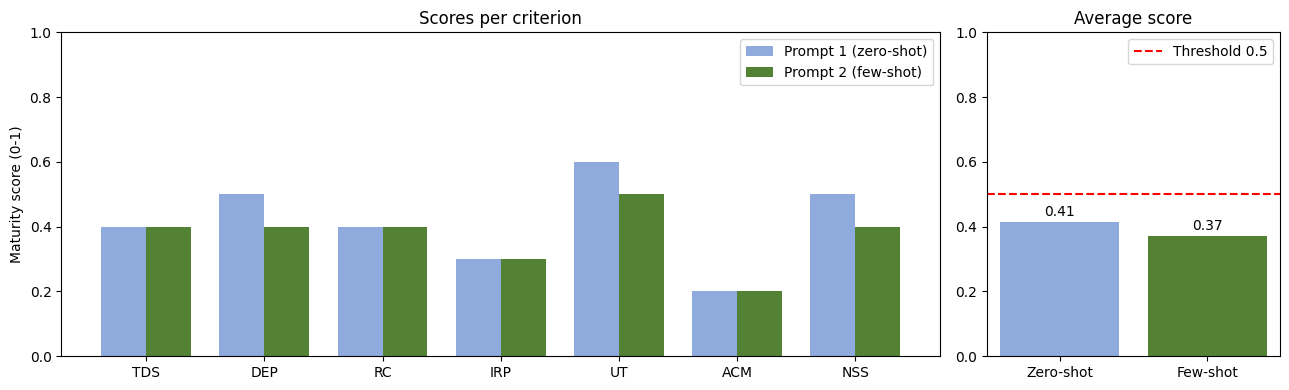

,Prompt,Average (code),Risk level (y),Weakest criteria,Label follows 0.5 rule,Borderline
0,1 - zero-shot,0.414,High,"[ACM, IRP]",True,False
1,2 - few-shot,0.371,High,"[ACM, IRP]",True,False


In [ ]:
def compare_runs(run_a, run_b):
    scores_a = run_a["result"]["scores"]
    scores_b = run_b["result"]["scores"]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})

    x = range(len(CRITERIA))
    w = 0.38
    axes[0].bar([i - w / 2 for i in x], [scores_a[c] for c in CRITERIA], w, label="Prompt 1 (zero-shot)", color="#8FAADC")
    axes[0].bar([i + w / 2 for i in x], [scores_b[c] for c in CRITERIA], w, label="Prompt 2 (few-shot)", color="#548235")
    axes[0].set_xticks(list(x))
    axes[0].set_xticklabels(CRITERIA)
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel("Maturity score (0-1)")
    axes[0].set_title("Scores per criterion")
    axes[0].legend()

    avgs = [run_a["check"]["avg_code"], run_b["check"]["avg_code"]]
    axes[1].bar(["Zero-shot", "Few-shot"], avgs, color=["#8FAADC", "#548235"])
    axes[1].axhline(THRESHOLD, color="red", linestyle="--", label="Threshold 0.5")
    axes[1].set_ylim(0, 1)
    axes[1].set_title("Average score")
    axes[1].legend()
    for i, v in enumerate(avgs):
        axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center")

    plt.tight_layout()
    plt.show()

    table = pd.DataFrame({
        "Prompt": ["1 - zero-shot", "2 - few-shot"],
        "Average (code)": avgs,
        "Risk level (y)": [run_a["result"]["risk_level"], run_b["result"]["risk_level"]],
        "Weakest criteria": [run_a["result"]["weakest_criteria"], run_b["result"]["weakest_criteria"]],
        "Label follows 0.5 rule": [run_a["check"]["label_matches"], run_b["check"]["label_matches"]],
        "Borderline": [run_a["check"]["borderline"], run_b["check"]["borderline"]],
    })
    return table

compare_runs(run_1, run_2)

## 8.  Consistency test

A language model can give slightly different scores each time. This cell runs each prompt several times and shows how much the average and the label change. It uses `N_RUNS * 2` extra API calls; set `RUN_CONSISTENCY_TEST = False` to skip it.

The temperature is set to 0.7 here on purpose, so that variation is visible. Near the threshold, a small change in one score can flip the label.

In [ ]:
RUN_CONSISTENCY_TEST = True
N_RUNS = 5

if RUN_CONSISTENCY_TEST:
    rows = []
    for name, builder in [("1 - zero-shot", build_prompt_1), ("2 - few-shot", build_prompt_2)]:
        for i in range(N_RUNS):
            res = call_gemini(builder(NEW_X), temperature=0.7)
            chk = check_reasoning(res)
            rows.append({"Prompt": name, "Run": i + 1, "Average (code)": chk["avg_code"], "Label (code)": chk["label_code"]})
    consistency = pd.DataFrame(rows)
    display(consistency.pivot(index="Run", columns="Prompt", values="Average (code)"))
    summary = consistency.groupby("Prompt").agg(
        mean_avg=("Average (code)", "mean"),
        std_avg=("Average (code)", "std"),
        high_share=("Label (code)", lambda s: (s == "High").mean()),
    ).round(3)
    print("Summary (high_share = share of runs labelled High):")
    display(summary)

  Gemini busy or limited (429) on gemini-3.6-flash. Waiting 5s (attempt 1/2)...
  Gemini busy or limited (429) on gemini-3.6-flash. Waiting 5s (attempt 1/2)...
  Gemini busy or limited (429) on gemini-3.8-flash. Waiting 5s (attempt 1/2)...
  Gemini busy or limited (429) on gemini-flash-latest. Waiting 5s (attempt 1/2)...
  Gemini busy or limited (429) on gemini-omni-flash-preview. Waiting 5s (attempt 1/2)...
  Gemini busy or limited (429) on gemini-omni-1.2-flash. Waiting 5s (attempt 1/2)...
  Gemini busy or limited (429) on gemini-omni-1.1-flash. Waiting 5s (attempt 1/2)...
  Gemini busy or limited (429) on gemini-3.7-flash. Waiting 5s (attempt 1/2)...


Prompt,1 - zero-shot,2 - few-shot
Run,,
1,0.414,0.357
2,0.386,0.357
3,0.429,0.357
4,0.414,0.357
5,0.414,0.357


Summary (high_share = share of runs labelled High):


,mean_avg,std_avg,high_share
Prompt,,,
1 - zero-shot,0.411,0.016,1.0
2 - few-shot,0.357,0.000,1.0


## 9. Reflection

**What the system does.** The system is a single AI agent that receives a text description of an airport's cybersecurity governance (X) and returns a Low or High risk level (y), together with scores for the seven criteria from Mizrak & Akkartal, an explanation and prioritised recommendations. A risk level is Low when the average maturity score is at least 0.5.

**How Gemini and prompt engineering were used.** Gemini (gemini-3.6-flash in my run) reads the free text, finds evidence for each criterion and turns it into scores. Prompt engineering defines the four stages, the JSON output format and the decision rule; the zero-shot prompt gives only instructions, while the few-shot prompt adds five known (X, y) pairs from Lab 1.2.

**What worked well.** Both prompts classified the new airport as High risk (zero-shot average 0.41, few-shot average 0.37), with ACM and IRP as the weakest criteria, and the code check confirmed that every average and label followed the 0.5 rule. In the consistency test (5 runs, temperature 0.7), the few-shot prompt was more stable (standard deviation 0.000 against 0.016) and gave slightly stricter scores.

**What could be improved.** This is a single observation with five runs per prompt, so it does not prove that few-shot is better in general, and the examples may anchor the scores too strongly. The airport was also far from the threshold for Gemini (0.37 to 0.41), so the test does not show how the agent behaves on borderline cases. Next steps would be a larger test set with borderline cases, real audit descriptions and human labels from several raters.
